In [2]:
import pandas as pd
from pathlib import Path

# Path to the training dataset
data_path = Path("../data/water_train.csv")

# Load the dataset
df = pd.read_csv(data_path)

# Display the first five rows
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,0.483566,0.615597,0.513964,0.777394,0.354601,0.335319,0.367332,0.514102,0.617313,1
1,0.639608,0.516021,0.380558,0.390190,0.628308,0.157487,0.451506,0.558650,0.834925,0
2,0.370117,0.847246,0.623556,0.992911,0.145461,0.345829,0.334781,0.402932,0.590146,1
3,0.545159,0.261747,0.292037,0.535522,0.436155,0.713600,0.667406,0.471880,0.138483,0
4,0.610883,0.525235,0.465619,0.475133,0.634338,0.196409,0.623423,0.520589,0.755856,0


In [3]:
# Dataset dimensions
print("Shape:", df.shape)

# Column types and non-null counts
print("\nDataset information:")
df.info()

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Target class distribution
print("\nPotability distribution:")
print(df["Potability"].value_counts())

Shape: (1508, 10)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1508 entries, 0 to 1507
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               1508 non-null   float64
 1   Hardness         1508 non-null   float64
 2   Solids           1508 non-null   float64
 3   Chloramines      1508 non-null   float64
 4   Sulfate          1508 non-null   float64
 5   Conductivity     1508 non-null   float64
 6   Organic_carbon   1508 non-null   float64
 7   Trihalomethanes  1508 non-null   float64
 8   Turbidity        1508 non-null   float64
 9   Potability       1508 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 117.9 KB

Missing values:
ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64

Potability distribu

In [4]:
# Summary statistics for the input features
df.drop(columns="Potability").describe().T

,count,mean,std,min,25%,50%,75%,max
ph,1508.0,0.500149,0.113909,0.000000,0.427010,0.496297,0.569402,1.0
Hardness,1508.0,0.503259,0.131456,0.000000,0.425317,0.507005,0.584094,1.0
Solids,1508.0,0.383097,0.155373,0.000000,0.271102,0.360893,0.475623,1.0
Chloramines,1508.0,0.486529,0.132788,0.000000,0.402804,0.487083,0.571714,1.0
Sulfate,1508.0,0.581444,0.116578,0.000000,0.509391,0.578913,0.652099,1.0
Conductivity,1508.0,0.407448,0.145924,0.000000,0.299284,0.403767,0.507814,1.0
Organic_carbon,1508.0,0.491162,0.132618,0.087553,0.402528,0.489847,0.585090,1.0
Trihalomethanes,1508.0,0.500084,0.142015,0.000000,0.406507,0.497608,0.596025,1.0
Turbidity,1508.0,0.496433,0.153230,0.000000,0.394065,0.496085,0.603611,1.0


In [6]:
# Load the second dataset
test_path = Path("../data/water_test.csv")
df_test = pd.read_csv(test_path)

print("Test dataset shape:", df_test.shape)
print("\nColumns:", df_test.columns.tolist())
print("\nMissing values:")
print(df_test.isnull().sum())

df_test.head()

Test dataset shape: (503, 10)

Columns: ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability']

Missing values:
ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,0.643654,0.441300,0.314381,0.439304,0.514545,0.356685,0.377248,0.202914,0.520358,0
1,0.388934,0.470876,0.506122,0.524364,0.561537,0.142913,0.249922,0.401487,0.219973,0
2,0.500441,0.341251,0.327766,0.188748,0.435599,0.264798,0.553461,0.614468,0.395611,0
3,0.741027,0.181668,0.391790,0.576905,0.507648,0.383104,0.430960,0.495191,0.715063,0
4,0.354933,0.485801,0.343607,0.397903,0.553464,0.435234,0.353392,0.352280,0.486068,0


In [7]:
from sklearn.model_selection import train_test_split

# Split the supplied training dataset
df_train, df_val = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["Potability"]
)

print("Training samples:", len(df_train))
print("Validation samples:", len(df_val))
print("Test samples:", len(df_test))

Training samples: 1206
Validation samples: 302
Test samples: 503


In [8]:
import torch
from torch.utils.data import Dataset

class WaterDataset(Dataset):
    def __init__(self, dataframe):
        super().__init__()

        self.features = torch.tensor(
            dataframe.drop(columns="Potability").values,
            dtype=torch.float32
        )

        self.labels = torch.tensor(
            dataframe["Potability"].values,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.features[idx], self.labels[idx]

In [9]:
# Create dataset instances
train_dataset = WaterDataset(df_train)
val_dataset = WaterDataset(df_val)
test_dataset = WaterDataset(df_test)

# Verify dataset sizes
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

# Inspect the first training sample
features, label = train_dataset[0]

print("\nFeature shape:", features.shape)
print("Feature dtype:", features.dtype)
print("Label:", label)
print("Label dtype:", label.dtype)

Training samples: 1206
Validation samples: 302
Test samples: 503

Feature shape: torch.Size([9])
Feature dtype: torch.float32
Label: tensor(1.)
Label dtype: torch.float32


In [10]:
from torch.utils.data import DataLoader

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

# Inspect one training batch
features, labels = next(iter(train_loader))

print("Features shape:", features.shape)
print("Labels shape:", labels.shape)

Features shape: torch.Size([32, 9])
Labels shape: torch.Size([32])


In [11]:
import torch.nn as nn

class WaterPotabilityNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(9, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

# Instantiate the model
model = WaterPotabilityNN()

print(model)

WaterPotabilityNN(
  (fc1): Linear(in_features=9, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
)


In [12]:
import torch.optim as optim

# Binary classification loss
criterion = nn.BCEWithLogitsLoss()

# Adam optimiser
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Loss function:", criterion)
print("Optimiser:", optimizer.__class__.__name__)

Loss function: BCEWithLogitsLoss()
Optimiser: Adam


In [13]:
num_epochs = 50

train_losses = []

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for features, labels in train_loader:

        # Z - Zero gradients
        optimizer.zero_grad()

        # F - Forward pass
        outputs = model(features)

        # L - Calculate loss
        loss = criterion(outputs, labels.view(-1, 1))

        # B - Backpropagation
        loss.backward()

        # S - Update parameters
        optimizer.step()

        running_loss += loss.item() * features.size(0)

    # Average training loss per sample
    epoch_loss = running_loss / len(train_dataset)
    train_losses.append(epoch_loss)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}")

Epoch 5/50, Loss: 0.6734
Epoch 10/50, Loss: 0.6708
Epoch 15/50, Loss: 0.6657
Epoch 20/50, Loss: 0.6608
Epoch 25/50, Loss: 0.6489
Epoch 30/50, Loss: 0.6386
Epoch 35/50, Loss: 0.6278
Epoch 40/50, Loss: 0.6150
Epoch 45/50, Loss: 0.6049
Epoch 50/50, Loss: 0.6060


In [14]:
# Switch to evaluation mode
model.eval()

val_loss = 0.0

# Disable gradient calculations
with torch.no_grad():
    for features, labels in val_loader:

        # Forward pass
        outputs = model(features)

        # Calculate loss
        loss = criterion(outputs, labels.view(-1, 1))

        val_loss += loss.item() * features.size(0)

# Average validation loss
val_loss /= len(val_dataset)

print(f"Final training loss: {train_losses[-1]:.4f}")
print(f"Validation loss:     {val_loss:.4f}")

Final training loss: 0.6060
Validation loss:     0.6271


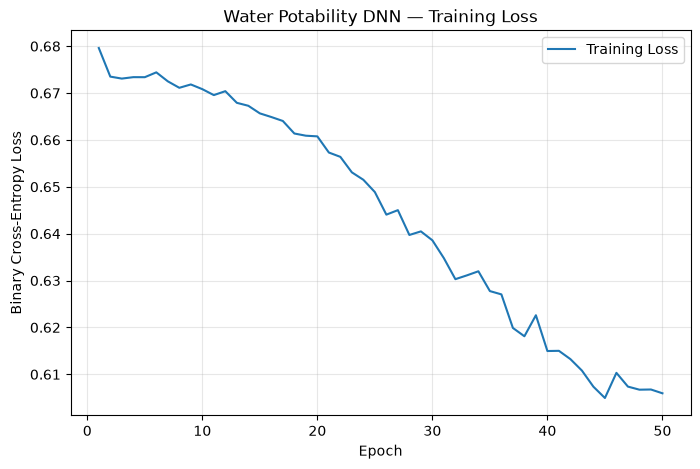

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, num_epochs + 1),
    train_losses,
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Water Potability DNN — Training Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [16]:
# Reinitialise the model and optimiser
torch.manual_seed(42)

model = WaterPotabilityNN()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 50

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    # Training
    model.train()
    running_train_loss = 0.0

    for features, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(features)
        loss = criterion(outputs, labels.view(-1, 1))

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * features.size(0)

    train_losses.append(running_train_loss / len(train_dataset))

    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for features, labels in val_loader:
            outputs = model(features)
            loss = criterion(outputs, labels.view(-1, 1))

            running_val_loss += loss.item() * features.size(0)

    val_losses.append(running_val_loss / len(val_dataset))

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch+1}/{num_epochs} | "
            f"Train Loss: {train_losses[-1]:.4f} | "
            f"Val Loss: {val_losses[-1]:.4f}"
        )

Epoch 5/50 | Train Loss: 0.6729 | Val Loss: 0.6732
Epoch 10/50 | Train Loss: 0.6692 | Val Loss: 0.6692
Epoch 15/50 | Train Loss: 0.6615 | Val Loss: 0.6626
Epoch 20/50 | Train Loss: 0.6484 | Val Loss: 0.6580
Epoch 25/50 | Train Loss: 0.6334 | Val Loss: 0.6482
Epoch 30/50 | Train Loss: 0.6214 | Val Loss: 0.6362
Epoch 35/50 | Train Loss: 0.6085 | Val Loss: 0.6212
Epoch 40/50 | Train Loss: 0.6010 | Val Loss: 0.6216
Epoch 45/50 | Train Loss: 0.5948 | Val Loss: 0.6155
Epoch 50/50 | Train Loss: 0.5868 | Val Loss: 0.6057


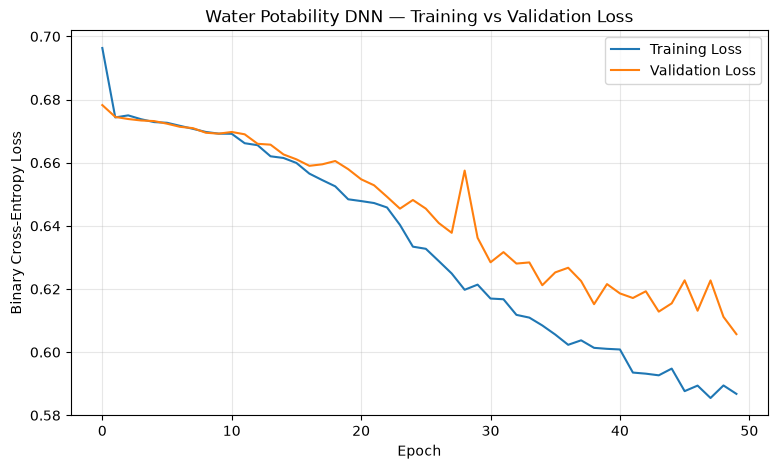

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Water Potability DNN — Training vs Validation Loss")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [18]:
from sklearn.metrics import classification_report, confusion_matrix

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for features, labels in val_loader:

        # Raw model outputs (logits)
        logits = model(features)

        # Convert logits into probabilities
        probabilities = torch.sigmoid(logits)

        # Convert probabilities into binary predictions
        predictions = (probabilities >= 0.5).int()

        all_labels.extend(labels.numpy().astype(int))
        all_predictions.extend(predictions.view(-1).numpy())

# Classification metrics
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Not Potable", "Potable"],
    zero_division=0
))

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

              precision    recall  f1-score   support

 Not Potable       0.69      0.89      0.78       181
     Potable       0.71      0.40      0.51       121

    accuracy                           0.69       302
   macro avg       0.70      0.64      0.64       302
weighted avg       0.70      0.69      0.67       302

Confusion Matrix:
[[161  20]
 [ 73  48]]


In [19]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

X_train = df_train.drop(columns="Potability")
y_train = df_train["Potability"]

X_val = df_val.drop(columns="Potability")
y_val = df_val["Potability"]

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_val)

print("Baseline accuracy:",
      round(accuracy_score(y_val, baseline_predictions), 4))

print("Baseline macro F1:",
      round(f1_score(y_val, baseline_predictions, average="macro"), 4))

print("DNN accuracy:",
      round(accuracy_score(all_labels, all_predictions), 4))

print("DNN macro F1:",
      round(f1_score(all_labels, all_predictions, average="macro"), 4))

Baseline accuracy: 0.5993
Baseline macro F1: 0.3747
DNN accuracy: 0.6921
DNN macro F1: 0.6419


In [20]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

model.eval()

all_probabilities = []
all_labels = []

with torch.no_grad():
    for features, labels in val_loader:
        logits = model(features)
        probabilities = torch.sigmoid(logits)

        all_probabilities.extend(probabilities.view(-1).numpy())
        all_labels.extend(labels.numpy().astype(int))

all_probabilities = np.array(all_probabilities)
all_labels = np.array(all_labels)

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    predictions = (all_probabilities >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision_score(all_labels, predictions, zero_division=0):.3f} | "
        f"Recall: {recall_score(all_labels, predictions, zero_division=0):.3f} | "
        f"F1: {f1_score(all_labels, predictions, zero_division=0):.3f}"
    )

Threshold: 0.3 | Precision: 0.460 | Recall: 0.810 | F1: 0.587
Threshold: 0.4 | Precision: 0.527 | Recall: 0.562 | F1: 0.544
Threshold: 0.5 | Precision: 0.706 | Recall: 0.397 | F1: 0.508
Threshold: 0.6 | Precision: 0.756 | Recall: 0.256 | F1: 0.383
Threshold: 0.7 | Precision: 0.952 | Recall: 0.165 | F1: 0.282


Validation ROC-AUC: 0.6883


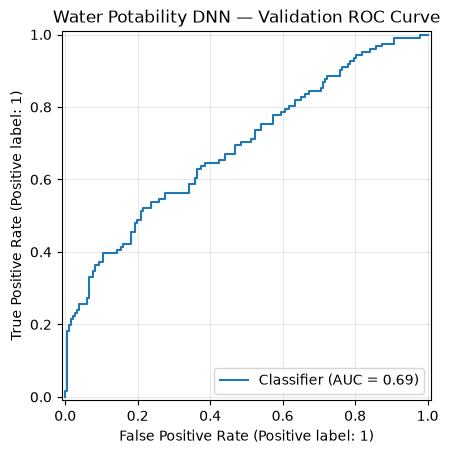

In [22]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay
import matplotlib.pyplot as plt

# Calculate ROC-AUC using predicted probabilities
auc = roc_auc_score(all_labels, all_probabilities)

print(f"Validation ROC-AUC: {auc:.4f}")

# Plot the ROC curve
RocCurveDisplay.from_predictions(
    all_labels,
    all_probabilities
)

plt.title("Water Potability DNN — Validation ROC Curve")
plt.grid(alpha=0.3)
plt.show()

In [23]:
class WaterPotabilityNN_BN(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(9, 64)
        self.bn1 = nn.BatchNorm1d(64)

        self.fc2 = nn.Linear(64, 32)
        self.bn2 = nn.BatchNorm1d(32)

        self.fc3 = nn.Linear(32, 1)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.bn1(self.fc1(x)))
        x = self.relu(self.bn2(self.fc2(x)))
        x = self.fc3(x)

        return x


# Create the new model
model_bn = WaterPotabilityNN_BN()

print(model_bn)

WaterPotabilityNN_BN(
  (fc1): Linear(in_features=9, out_features=64, bias=True)
  (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (bn2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
)


In [24]:
# Configure optimiser
optimizer_bn = optim.Adam(model_bn.parameters(), lr=0.001)

num_epochs = 50
train_losses_bn = []
val_losses_bn = []

for epoch in range(num_epochs):

    # Training
    model_bn.train()
    running_train_loss = 0.0

    for features, labels in train_loader:
        optimizer_bn.zero_grad()

        outputs = model_bn(features)
        loss = criterion(outputs, labels.view(-1, 1))

        loss.backward()
        optimizer_bn.step()

        running_train_loss += loss.item() * features.size(0)

    train_losses_bn.append(running_train_loss / len(train_dataset))

    # Validation
    model_bn.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for features, labels in val_loader:
            outputs = model_bn(features)
            loss = criterion(outputs, labels.view(-1, 1))

            running_val_loss += loss.item() * features.size(0)

    val_losses_bn.append(running_val_loss / len(val_dataset))

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch+1}/{num_epochs} | "
            f"Train Loss: {train_losses_bn[-1]:.4f} | "
            f"Val Loss: {val_losses_bn[-1]:.4f}"
        )

Epoch 5/50 | Train Loss: 0.5952 | Val Loss: 0.6150
Epoch 10/50 | Train Loss: 0.5578 | Val Loss: 0.6117
Epoch 15/50 | Train Loss: 0.5270 | Val Loss: 0.6240
Epoch 20/50 | Train Loss: 0.5107 | Val Loss: 0.6435
Epoch 25/50 | Train Loss: 0.5007 | Val Loss: 0.6579
Epoch 30/50 | Train Loss: 0.4885 | Val Loss: 0.6623
Epoch 35/50 | Train Loss: 0.4749 | Val Loss: 0.6818
Epoch 40/50 | Train Loss: 0.4582 | Val Loss: 0.6906
Epoch 45/50 | Train Loss: 0.4293 | Val Loss: 0.6924
Epoch 50/50 | Train Loss: 0.4294 | Val Loss: 0.6879


In [25]:
import numpy as np

best_epoch = np.argmin(val_losses_bn) + 1
best_val_loss = np.min(val_losses_bn)

print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Final validation loss: {val_losses_bn[-1]:.4f}")

Best epoch: 8
Best validation loss: 0.6078
Final validation loss: 0.6879


In [26]:
import copy

# Start with a fresh BatchNorm model
torch.manual_seed(42)
model_bn_es = WaterPotabilityNN_BN()

optimizer_bn_es = optim.Adam(
    model_bn_es.parameters(),
    lr=0.001
)

num_epochs = 50
patience = 7

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
best_weights = None

train_losses_bn_es = []
val_losses_bn_es = []

for epoch in range(num_epochs):

    # Training
    model_bn_es.train()
    running_train_loss = 0.0

    for features, labels in train_loader:
        optimizer_bn_es.zero_grad()

        outputs = model_bn_es(features)
        loss = criterion(outputs, labels.view(-1, 1))

        loss.backward()
        optimizer_bn_es.step()

        running_train_loss += loss.item() * features.size(0)

    train_losses_bn_es.append(
        running_train_loss / len(train_dataset)
    )

    # Validation
    model_bn_es.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for features, labels in val_loader:
            outputs = model_bn_es(features)
            loss = criterion(outputs, labels.view(-1, 1))

            running_val_loss += loss.item() * features.size(0)

    epoch_val_loss = running_val_loss / len(val_dataset)
    val_losses_bn_es.append(epoch_val_loss)

    # Check for improvement
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        # Save model weights and BatchNorm statistics
        best_weights = copy.deepcopy(model_bn_es.state_dict())

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

# Restore the best model
model_bn_es.load_state_dict(best_weights)
model_bn_es.eval()

print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")

Early stopping at epoch 13
Best epoch: 6
Best validation loss: 0.6068


In [27]:
from sklearn.metrics import classification_report, roc_auc_score

model_bn_es.eval()

bn_labels = []
bn_predictions = []
bn_probabilities = []

with torch.no_grad():
    for features, labels in val_loader:
        logits = model_bn_es(features)
        probabilities = torch.sigmoid(logits).view(-1)

        predictions = (probabilities >= 0.5).int()

        bn_labels.extend(labels.numpy().astype(int))
        bn_predictions.extend(predictions.numpy())
        bn_probabilities.extend(probabilities.numpy())

print("BatchNorm + Early Stopping Classification Report:")
print(classification_report(
    bn_labels,
    bn_predictions,
    target_names=["Not Potable", "Potable"],
    zero_division=0
))

print(
    "ROC-AUC:",
    round(roc_auc_score(bn_labels, bn_probabilities), 4)
)

BatchNorm + Early Stopping Classification Report:
              precision    recall  f1-score   support

 Not Potable       0.67      0.88      0.76       181
     Potable       0.67      0.35      0.46       121

    accuracy                           0.67       302
   macro avg       0.67      0.62      0.61       302
weighted avg       0.67      0.67      0.64       302

ROC-AUC: 0.6998


In [ ]:
class WaterPotabilityNN_BN_Dropout(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(9, 64)
        self.bn1 = nn.BatchNorm1d(64)

        self.fc2 = nn.Linear(64, 32)
        self.bn2 = nn.BatchNorm1d(32)

        self.fc3 = nn.Linear(32, 1)

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=0.2)

    def forward(self, x):
        x = self.relu(self.bn1(self.fc1(x)))
        x = self.dropout(x)

        x = self.relu(self.bn2(self.fc2(x)))
        x = self.dropout(x)

        x = self.fc3(x)
        return x


model_bn_dropout = WaterPotabilityNN_BN_Dropout()

print(model_bn_dropout)

In [29]:
import copy

torch.manual_seed(42)

# Create a fresh BatchNorm + Dropout model
model_bn_dropout = WaterPotabilityNN_BN_Dropout()

optimizer_bn_dropout = optim.Adam(
    model_bn_dropout.parameters(),
    lr=0.001
)

num_epochs = 50
patience = 7

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
best_weights = None

train_losses_bn_dropout = []
val_losses_bn_dropout = []

for epoch in range(num_epochs):

    # Training
    model_bn_dropout.train()
    running_train_loss = 0.0

    for features, labels in train_loader:
        optimizer_bn_dropout.zero_grad()

        outputs = model_bn_dropout(features)
        loss = criterion(outputs, labels.view(-1, 1))

        loss.backward()
        optimizer_bn_dropout.step()

        running_train_loss += loss.item() * features.size(0)

    train_losses_bn_dropout.append(
        running_train_loss / len(train_dataset)
    )

    # Validation
    model_bn_dropout.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for features, labels in val_loader:
            outputs = model_bn_dropout(features)
            loss = criterion(outputs, labels.view(-1, 1))

            running_val_loss += loss.item() * features.size(0)

    epoch_val_loss = running_val_loss / len(val_dataset)
    val_losses_bn_dropout.append(epoch_val_loss)

    # Early stopping
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        best_weights = copy.deepcopy(
            model_bn_dropout.state_dict()
        )
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

# Restore the best model
model_bn_dropout.load_state_dict(best_weights)
model_bn_dropout.eval()

print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")

Early stopping at epoch 24
Best epoch: 17
Best validation loss: 0.6087


In [30]:
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    confusion_matrix
)

model_bn_dropout.eval()

dropout_labels = []
dropout_predictions = []
dropout_probabilities = []

with torch.no_grad():
    for features, labels in val_loader:

        logits = model_bn_dropout(features)
        probabilities = torch.sigmoid(logits).view(-1)

        predictions = (probabilities >= 0.5).int()

        dropout_labels.extend(labels.numpy().astype(int))
        dropout_predictions.extend(predictions.numpy())
        dropout_probabilities.extend(probabilities.numpy())

print("BatchNorm + Dropout Classification Report:")
print(classification_report(
    dropout_labels,
    dropout_predictions,
    target_names=["Not Potable", "Potable"],
    zero_division=0
))

print("ROC-AUC:", round(
    roc_auc_score(dropout_labels, dropout_probabilities), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(dropout_labels, dropout_predictions))

BatchNorm + Dropout Classification Report:
              precision    recall  f1-score   support

 Not Potable       0.67      0.90      0.77       181
     Potable       0.69      0.34      0.46       121

    accuracy                           0.68       302
   macro avg       0.68      0.62      0.61       302
weighted avg       0.68      0.68      0.64       302

ROC-AUC: 0.6836

Confusion Matrix:
[[163  18]
 [ 80  41]]


In [31]:
# Reinitialise the original architecture
torch.manual_seed(42)

model_wd = WaterPotabilityNN()

# Adam optimiser with weight decay
optimizer_wd = optim.Adam(
    model_wd.parameters(),
    lr=0.001,
    weight_decay=0.001
)

print(model_wd)
print("Weight decay:", optimizer_wd.param_groups[0]["weight_decay"])

WaterPotabilityNN(
  (fc1): Linear(in_features=9, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
)
Weight decay: 0.001


In [32]:
import copy

num_epochs = 50
patience = 7

best_val_loss_wd = float("inf")
best_epoch_wd = 0
epochs_without_improvement = 0
best_weights_wd = None

train_losses_wd = []
val_losses_wd = []

for epoch in range(num_epochs):

    # Training
    model_wd.train()
    running_train_loss = 0.0

    for features, labels in train_loader:
        optimizer_wd.zero_grad()

        outputs = model_wd(features)
        loss = criterion(outputs, labels.view(-1, 1))

        loss.backward()
        optimizer_wd.step()

        running_train_loss += loss.item() * features.size(0)

    train_losses_wd.append(
        running_train_loss / len(train_dataset)
    )

    # Validation
    model_wd.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for features, labels in val_loader:
            outputs = model_wd(features)
            loss = criterion(outputs, labels.view(-1, 1))

            running_val_loss += loss.item() * features.size(0)

    epoch_val_loss = running_val_loss / len(val_dataset)
    val_losses_wd.append(epoch_val_loss)

    # Early stopping
    if epoch_val_loss < best_val_loss_wd:
        best_val_loss_wd = epoch_val_loss
        best_epoch_wd = epoch + 1
        epochs_without_improvement = 0

        best_weights_wd = copy.deepcopy(
            model_wd.state_dict()
        )
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

# Restore the best weights
model_wd.load_state_dict(best_weights_wd)
model_wd.eval()

print(f"Best epoch: {best_epoch_wd}")
print(f"Best validation loss: {best_val_loss_wd:.4f}")

Best epoch: 50
Best validation loss: 0.6206


In [33]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

model_wd.eval()

wd_labels = []
wd_predictions = []
wd_probabilities = []

with torch.no_grad():
    for features, labels in val_loader:

        logits = model_wd(features)
        probabilities = torch.sigmoid(logits).view(-1)
        predictions = (probabilities >= 0.5).int()

        wd_labels.extend(labels.numpy().astype(int))
        wd_predictions.extend(predictions.numpy())
        wd_probabilities.extend(probabilities.numpy())

print("Weight Decay Model — Classification Report:")
print(classification_report(
    wd_labels,
    wd_predictions,
    target_names=["Not Potable", "Potable"],
    zero_division=0
))

print("ROC-AUC:",
      round(roc_auc_score(wd_labels, wd_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(wd_labels, wd_predictions))

Weight Decay Model — Classification Report:
              precision    recall  f1-score   support

 Not Potable       0.67      0.91      0.77       181
     Potable       0.71      0.33      0.45       121

    accuracy                           0.68       302
   macro avg       0.69      0.62      0.61       302
weighted avg       0.69      0.68      0.64       302

ROC-AUC: 0.6729

Confusion Matrix:
[[165  16]
 [ 81  40]]


In [34]:
import sys
from pathlib import Path

# Allow imports from the project root
sys.path.insert(0, str(Path.cwd().parent))

from src.model import WaterPotabilityNN
from src.train import train_model

# Create a fresh model
torch.manual_seed(42)
model_test = WaterPotabilityNN()

# Configure loss and optimiser
criterion_test = nn.BCEWithLogitsLoss()
optimizer_test = optim.Adam(model_test.parameters(), lr=0.001)

# Train using our reusable function
model_test, train_history, val_history = train_model(
    model=model_test,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_test,
    optimizer=optimizer_test,
    num_epochs=50,
    patience=7
)

Epoch 5/50 | Train: 0.6729 | Val: 0.6732
Epoch 10/50 | Train: 0.6692 | Val: 0.6692
Epoch 15/50 | Train: 0.6615 | Val: 0.6626
Epoch 20/50 | Train: 0.6484 | Val: 0.6580
Epoch 25/50 | Train: 0.6334 | Val: 0.6482
Epoch 30/50 | Train: 0.6214 | Val: 0.6362
Epoch 35/50 | Train: 0.6085 | Val: 0.6212
Epoch 40/50 | Train: 0.6010 | Val: 0.6216
Epoch 45/50 | Train: 0.5948 | Val: 0.6155
Epoch 50/50 | Train: 0.5868 | Val: 0.6057
Best epoch: 50
Best validation loss: 0.6057


In [35]:
from src.evaluate import evaluate_model

# Evaluate our trained baseline DNN
results_baseline = evaluate_model(
    model=model_test,
    data_loader=val_loader,
    threshold=0.5
)

              precision    recall  f1-score   support

 Not Potable       0.69      0.89      0.78       181
     Potable       0.71      0.40      0.51       121

    accuracy                           0.69       302
   macro avg       0.70      0.64      0.64       302
weighted avg       0.70      0.69      0.67       302

ROC-AUC: 0.6883

Confusion Matrix:
[[161  20]
 [ 73  48]]


In [36]:
import torch
from pathlib import Path

# Create the models directory if it doesn't exist
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save the trained model weights
model_path = models_dir / "baseline_dnn.pt"

torch.save(model_test.state_dict(), model_path)

print(f"Model saved to: {model_path}")

Model saved to: ..\models\baseline_dnn.pt


In [37]:
# Create a new instance of the baseline architecture
model_reloaded = WaterPotabilityNN()

# Load the saved weights
model_reloaded.load_state_dict(
    torch.load(model_path, map_location="cpu", weights_only=True)
)

# Switch to evaluation mode
model_reloaded.eval()

# Evaluate the reloaded model
results_reloaded = evaluate_model(
    model=model_reloaded,
    data_loader=val_loader,
    threshold=0.5
)

# Verify the metrics match the original model
for metric in ["accuracy", "macro_f1", "roc_auc"]:
    assert abs(results_reloaded[metric] - results_baseline[metric]) < 1e-10

print("\nSaved model verification: PASSED")

              precision    recall  f1-score   support

 Not Potable       0.69      0.89      0.78       181
     Potable       0.71      0.40      0.51       121

    accuracy                           0.69       302
   macro avg       0.70      0.64      0.64       302
weighted avg       0.70      0.69      0.67       302

ROC-AUC: 0.6883

Confusion Matrix:
[[161  20]
 [ 73  48]]

Saved model verification: PASSED
